In [1]:
import numpy as np
import torch as tc
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from datetime import datetime

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import accuracy_score

# from titanic_XGBoost import *

In [2]:
plt.rcParams.update({
    'font.size': 14,             # 所有字体的基准大小
    'axes.titlesize': 16,        # 子图标题（ax.set_title）
    'axes.labelsize': 13,        # x/y轴标签（ax.set_xlabel / set_ylabel）
    'xtick.labelsize': 13,       # x轴刻度字体
    'ytick.labelsize': 13,       # y轴刻度字体
    'legend.fontsize': 12,       # 图例字体
    'figure.titlesize': 20      # fig.suptitle 总标题字体
})

In [3]:
path = '/Users/eta/.cache/kagglehub/competitions/spaceship-titanic'
dataset = pd.read_csv(path + '/train.csv')

---

In [4]:
def getData(dataset: pd.DataFrame, istest=False):
    dataset_df = dataset.copy()
    # creat the new feature
    dataset_df['PassengerId'] = [int(i[:4]) for i in dataset_df['PassengerId']]
    dataset_df[["Deck", "Cabin_num", "Side"]] = dataset_df["Cabin"].str.split("/", expand=True)
    dataset_df['Cabin_num'] = dataset_df['Cabin_num'].fillna('0')
    dataset_df['Cabin_num'] = dataset_df['Cabin_num'].astype(int)

    # for Age: replace the nan with the mean value.
    dataset_df['Age'] = dataset_df['Age'].fillna(dataset_df['Age'].mean().round())

    # for bill: replace the nan with zero value. 
    for name in ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']:
        dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna(0)

    dataset_df['Cost'] = dataset_df[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].sum(axis=1)

    # for category: using the one-hot encoding.
    for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP', 'Deck', 'Side']:
    #     print(len(dataset_df[f'{name}'].unique()), dataset_df[f'{name}'].unique())
        dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna('Missing')

    # one-hot encoding:
    for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP', 'Deck', 'Side']:
    #     print(len(dataset_df[name].unique()), dataset_df[name].unique())
        for key in dataset_df[name].unique():
            dataset_df[f'{name}_{key}'] = 0
            dataset_df.loc[dataset_df[name] == key, f'{name}_{key}'] = 1

        dataset_df.drop(columns=[name], inplace=True)

    # dorp the meanless columns
    dataset_df = dataset_df.drop(['Cabin', 'Name'], axis=1)

    if istest:
        return dataset_df
    else:
        dataset_x = dataset_df.drop(columns=['Transported'])
        dataset_y = dataset_df['Transported']

        return dataset_x, dataset_y

### XGBoost

In [5]:
dataset_x, dataset_y = getData(dataset)

x_train_df, x_val_df, y_train_df, y_val_df = train_test_split(
    dataset_x,
    dataset_y,
    test_size=0.2,
    random_state=42,
#     stratify=dataset_y
)

print(x_train_df.shape)
x_train = np.array(x_train_df)
y_train = np.array(y_train_df)
x_val = np.array(x_val_df)
y_val = np.array(y_val_df)

(6954, 35)


In [6]:
x_train.shape

(6954, 35)

In [9]:
lr = 0.005
lamda = 1.0
gamma = 0

In [10]:
xgboost = XGBoost(lr, gamma, lamda)

In [11]:
xgboost.run(x_train, y_train, x_val, y_val, 3000)

start 0th iteration!
start 1th iteration!
start 2th iteration!
start 3th iteration!
start 4th iteration!
start 5th iteration!
start 6th iteration!
start 7th iteration!
start 8th iteration!
start 9th iteration!
start 10th iteration!
start 11th iteration!
start 12th iteration!
start 13th iteration!
start 14th iteration!
start 15th iteration!
start 16th iteration!
start 17th iteration!
start 18th iteration!
start 19th iteration!
start 20th iteration!
start 21th iteration!
start 22th iteration!
start 23th iteration!
start 24th iteration!
start 25th iteration!
start 26th iteration!
start 27th iteration!
start 28th iteration!
start 29th iteration!
start 30th iteration!
start 31th iteration!
start 32th iteration!
start 33th iteration!
start 34th iteration!
start 35th iteration!
start 36th iteration!
start 37th iteration!
start 38th iteration!
start 39th iteration!
start 40th iteration!
start 41th iteration!
start 42th iteration!
start 43th iteration!
start 44th iteration!
start 45th iteration

start 364th iteration!
start 365th iteration!
start 366th iteration!
start 367th iteration!
start 368th iteration!
start 369th iteration!
start 370th iteration!
start 371th iteration!
start 372th iteration!
start 373th iteration!
start 374th iteration!
start 375th iteration!
start 376th iteration!
start 377th iteration!
start 378th iteration!
start 379th iteration!
start 380th iteration!
start 381th iteration!
start 382th iteration!
start 383th iteration!
start 384th iteration!
start 385th iteration!
start 386th iteration!
start 387th iteration!
start 388th iteration!
start 389th iteration!
start 390th iteration!
start 391th iteration!
start 392th iteration!
start 393th iteration!
start 394th iteration!
start 395th iteration!
start 396th iteration!
start 397th iteration!
start 398th iteration!
start 399th iteration!
start 400th iteration!
start 401th iteration!
start 402th iteration!
start 403th iteration!
start 404th iteration!
start 405th iteration!
start 406th iteration!
start 407th

start 723th iteration!
start 724th iteration!
start 725th iteration!
start 726th iteration!
start 727th iteration!
start 728th iteration!
start 729th iteration!
start 730th iteration!
start 731th iteration!
start 732th iteration!
start 733th iteration!
start 734th iteration!
start 735th iteration!
start 736th iteration!
start 737th iteration!
start 738th iteration!
start 739th iteration!
start 740th iteration!
start 741th iteration!
start 742th iteration!
start 743th iteration!
start 744th iteration!
start 745th iteration!
start 746th iteration!
start 747th iteration!
start 748th iteration!
start 749th iteration!
start 750th iteration!
start 751th iteration!
start 752th iteration!
start 753th iteration!
start 754th iteration!
start 755th iteration!
start 756th iteration!
start 757th iteration!
start 758th iteration!
start 759th iteration!
start 760th iteration!
start 761th iteration!
start 762th iteration!
start 763th iteration!
start 764th iteration!
start 765th iteration!
start 766th

start 1079th iteration!
start 1080th iteration!
start 1081th iteration!
start 1082th iteration!
start 1083th iteration!
start 1084th iteration!
start 1085th iteration!
start 1086th iteration!
start 1087th iteration!
start 1088th iteration!
start 1089th iteration!
start 1090th iteration!
start 1091th iteration!
start 1092th iteration!
start 1093th iteration!
start 1094th iteration!
start 1095th iteration!
start 1096th iteration!
start 1097th iteration!
start 1098th iteration!
start 1099th iteration!
start 1100th iteration!
start 1101th iteration!
start 1102th iteration!
start 1103th iteration!
start 1104th iteration!
start 1105th iteration!
start 1106th iteration!
start 1107th iteration!
start 1108th iteration!
start 1109th iteration!
start 1110th iteration!
start 1111th iteration!
start 1112th iteration!
start 1113th iteration!
start 1114th iteration!
start 1115th iteration!
start 1116th iteration!
start 1117th iteration!
start 1118th iteration!
start 1119th iteration!
start 1120th ite

start 1424th iteration!
start 1425th iteration!
start 1426th iteration!
start 1427th iteration!
start 1428th iteration!
start 1429th iteration!
start 1430th iteration!
start 1431th iteration!
start 1432th iteration!
start 1433th iteration!
start 1434th iteration!
start 1435th iteration!
start 1436th iteration!
start 1437th iteration!
start 1438th iteration!
start 1439th iteration!
start 1440th iteration!
start 1441th iteration!
start 1442th iteration!
start 1443th iteration!
start 1444th iteration!
start 1445th iteration!
start 1446th iteration!
start 1447th iteration!
start 1448th iteration!
start 1449th iteration!
start 1450th iteration!
start 1451th iteration!
start 1452th iteration!
start 1453th iteration!
start 1454th iteration!
start 1455th iteration!
start 1456th iteration!
start 1457th iteration!
start 1458th iteration!
start 1459th iteration!
start 1460th iteration!
start 1461th iteration!
start 1462th iteration!
start 1463th iteration!
start 1464th iteration!
start 1465th ite

start 1769th iteration!
start 1770th iteration!
start 1771th iteration!
start 1772th iteration!
start 1773th iteration!
start 1774th iteration!
start 1775th iteration!
start 1776th iteration!
start 1777th iteration!
start 1778th iteration!
start 1779th iteration!
start 1780th iteration!
start 1781th iteration!
start 1782th iteration!
start 1783th iteration!
start 1784th iteration!
start 1785th iteration!
start 1786th iteration!
start 1787th iteration!
start 1788th iteration!
start 1789th iteration!
start 1790th iteration!
start 1791th iteration!
start 1792th iteration!
start 1793th iteration!
start 1794th iteration!
start 1795th iteration!
start 1796th iteration!
start 1797th iteration!
start 1798th iteration!
start 1799th iteration!
start 1800th iteration!
start 1801th iteration!
start 1802th iteration!
start 1803th iteration!
start 1804th iteration!
start 1805th iteration!
start 1806th iteration!
start 1807th iteration!
start 1808th iteration!
start 1809th iteration!
start 1810th ite

start 2114th iteration!
start 2115th iteration!
start 2116th iteration!
start 2117th iteration!
start 2118th iteration!
start 2119th iteration!
start 2120th iteration!
start 2121th iteration!
start 2122th iteration!
start 2123th iteration!
start 2124th iteration!
start 2125th iteration!
start 2126th iteration!
start 2127th iteration!
start 2128th iteration!
start 2129th iteration!
start 2130th iteration!
start 2131th iteration!
start 2132th iteration!
start 2133th iteration!
start 2134th iteration!
start 2135th iteration!
start 2136th iteration!
start 2137th iteration!
start 2138th iteration!
start 2139th iteration!
start 2140th iteration!
start 2141th iteration!
start 2142th iteration!
start 2143th iteration!
start 2144th iteration!
start 2145th iteration!
start 2146th iteration!
start 2147th iteration!
start 2148th iteration!
start 2149th iteration!
start 2150th iteration!
start 2151th iteration!
start 2152th iteration!
start 2153th iteration!
start 2154th iteration!
start 2155th ite

start 2457th iteration!
start 2458th iteration!
start 2459th iteration!
start 2460th iteration!
start 2461th iteration!
start 2462th iteration!
start 2463th iteration!
start 2464th iteration!
start 2465th iteration!
start 2466th iteration!
start 2467th iteration!
start 2468th iteration!
start 2469th iteration!
start 2470th iteration!
start 2471th iteration!
start 2472th iteration!
start 2473th iteration!
start 2474th iteration!
start 2475th iteration!
start 2476th iteration!
start 2477th iteration!
start 2478th iteration!
start 2479th iteration!
start 2480th iteration!
start 2481th iteration!
start 2482th iteration!
start 2483th iteration!
start 2484th iteration!
start 2485th iteration!
start 2486th iteration!
start 2487th iteration!
start 2488th iteration!
start 2489th iteration!
start 2490th iteration!
start 2491th iteration!
start 2492th iteration!
start 2493th iteration!
start 2494th iteration!
start 2495th iteration!
start 2496th iteration!
start 2497th iteration!
start 2498th ite

start 2799th iteration!
start 2800th iteration!
start 2801th iteration!
start 2802th iteration!
start 2803th iteration!
start 2804th iteration!
start 2805th iteration!
start 2806th iteration!
start 2807th iteration!
start 2808th iteration!
start 2809th iteration!
start 2810th iteration!
start 2811th iteration!
start 2812th iteration!
start 2813th iteration!
start 2814th iteration!
start 2815th iteration!
start 2816th iteration!
start 2817th iteration!
start 2818th iteration!
start 2819th iteration!
start 2820th iteration!
start 2821th iteration!
start 2822th iteration!
start 2823th iteration!
start 2824th iteration!
start 2825th iteration!
start 2826th iteration!
start 2827th iteration!
start 2828th iteration!
start 2829th iteration!
start 2830th iteration!
start 2831th iteration!
start 2832th iteration!
start 2833th iteration!
start 2834th iteration!
start 2835th iteration!
start 2836th iteration!
start 2837th iteration!
start 2838th iteration!
start 2839th iteration!
start 2840th ite

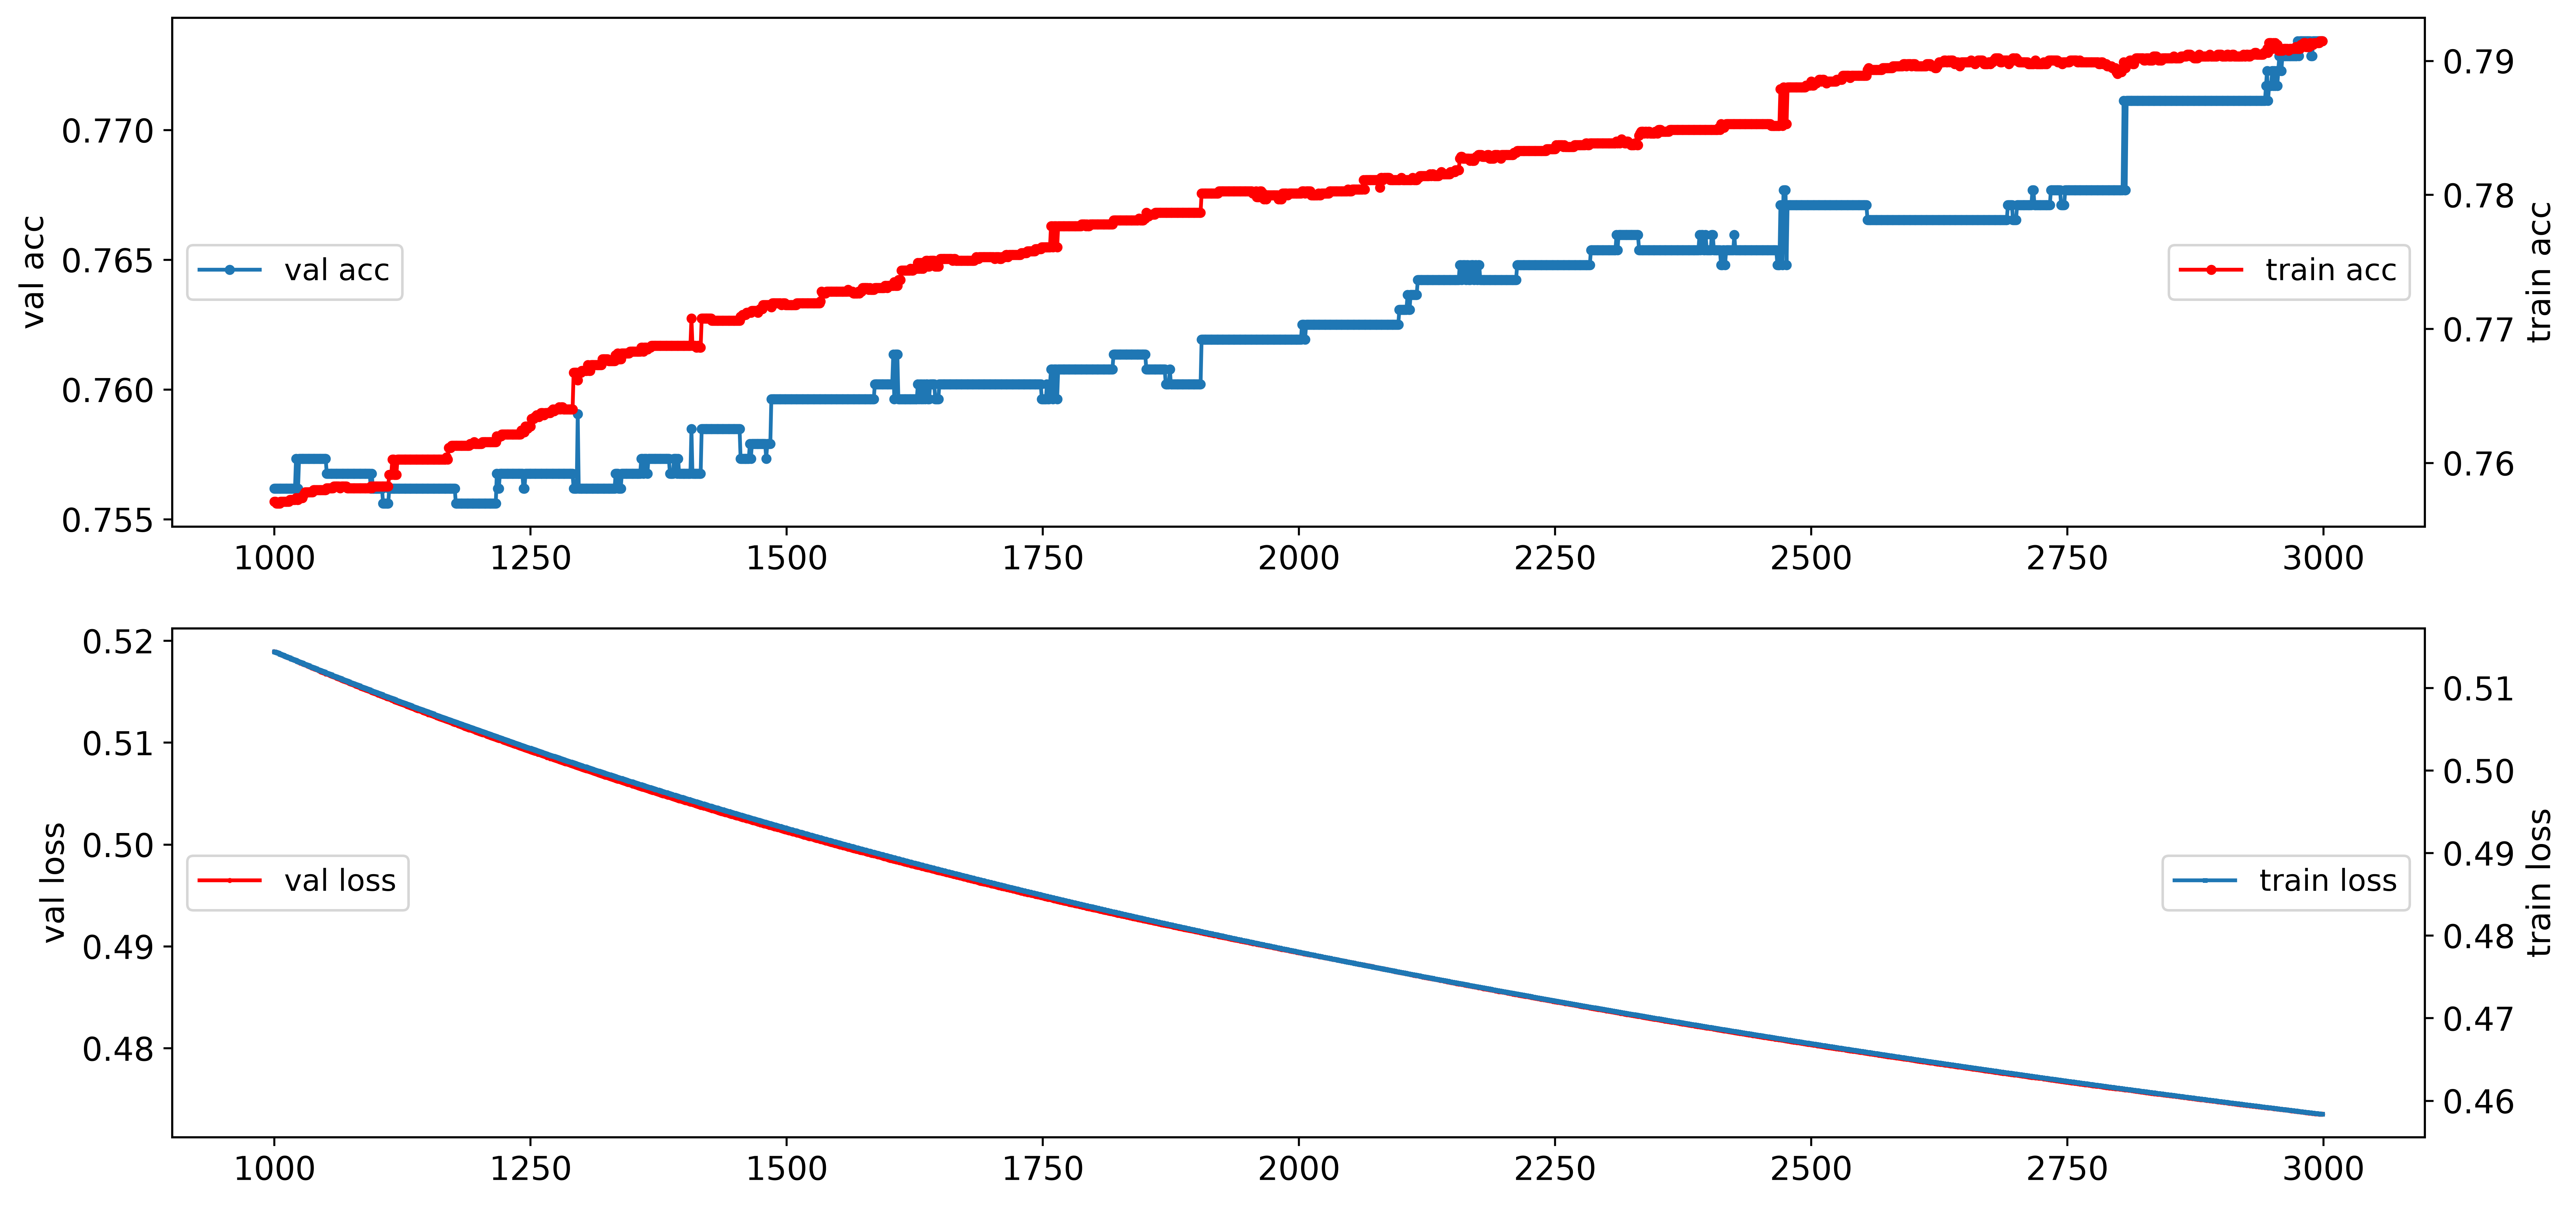

In [22]:
fig, ax = plt.subplots(nrows=2, dpi=500, figsize=(16, 8))

start_k = -2000

val_score_list = np.array(xgboost.log['val_acc'])
train_score_list = np.array(xgboost.log['train_acc'])
val_loss = np.array(xgboost.log['val_loss'])
train_loss = np.array(xgboost.log['train_loss'])

ax[0].plot(val_score_list[start_k:, 0], val_score_list[start_k:, 1], '.-', label='val acc')
# ax[0].plot([best_iteration] * 100, np.linspace(*ax[0].get_ylim(), 100))
ax[0].set_ylabel('val acc')
ax[0].legend(loc='center left')

axr = ax[0].twinx()
axr.plot(train_score_list[start_k:, 0], train_score_list[start_k:, 1], '.-', color='r', label='train acc')
axr.set_ylabel('train acc')
axr.legend(loc='center right')


axr = ax[1].twinx()
ax[1].plot(val_loss[start_k:, 0], val_loss[start_k:, 1], marker='o', color='r', markersize=1, label='val loss')
ax[1].set_ylabel('val loss')
ax[1].legend(loc='center left')
# ax[1].plot([best_iteration] * 100, np.linspace(*ax[1].get_ylim(), 100))
axr.plot(train_loss[start_k:, 0], train_loss[start_k:, 1], marker='s', markersize=1, label='train loss')
axr.set_ylabel('train loss')
axr.legend(loc='center right')

##### submit

In [17]:
test = pd.read_csv(path + '/test.csv')
sample = pd.read_csv(path + '/sample_submission.csv')

test_df = getData(test, istest=True)
test_df = test_df.reindex(columns=dataset_x.columns, fill_value=0)

In [18]:
test_pred = xgboost.test(np.array(test_df))

submit = sample.copy()
submit["Transported"] = test_pred

In [19]:
submit

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True
...,...,...
4272,9266_02,True
4273,9269_01,False
4274,9271_01,True
4275,9273_01,True


In [20]:
submit.to_csv(f'./data/submit_{datetime.now().isoformat()}.csv', index=False)
submit.to_csv(f'./submit.csv', index=False)

In [21]:
ls

__pycache__/                            titanic_alpha_GradientBoosting.ipynb
analysis/                               titanic_alpha_logic_registration.ipynb
data/                                   titanic_alpha_nueral_network.ipynb
submit.csv                              titanic_dataset.ipynb
titanic_alpha_AdaBoost.ipynb            titanic_XGBoost.ipynb
titanic_alpha_CART&RandomForest.ipynb   titanic_XGBoost.py
